# MLP Training Using Backpropagation for CIFAR10 dataset
<i> Wardatul Keskin | 301294696

In [3]:
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

## Data Loading and Exploration

In [4]:
# LOAD CIFAR dataset
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

In [5]:
# Dataset overview
print("Training data shape:", X_train.shape)
print("Test data shape:", X_test.shape)
print("Label shape (train):", y_train.shape)
print("Label shape (test):", y_test.shape)
print("Pixel value range:", X_train.min(), "to", X_train.max())

# Basic pixel statistics
print("\nPixel statistics (Train set):")
print(f"Mean: {np.mean(X_train):.2f}")
print(f"Standard Deviation: {np.std(X_train):.2f}")

Training data shape: (50000, 32, 32, 3)
Test data shape: (10000, 32, 32, 3)
Label shape (train): (50000, 1)
Label shape (test): (10000, 1)
Pixel value range: 0 to 255

Pixel statistics (Train set):
Mean: 120.71
Standard Deviation: 64.15


In [6]:
# Define class names
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Show class distribution in training data
unique, counts = np.unique(y_train, return_counts=True)
print("\nClass distribution in training data:")
for i in range(len(class_names)):
    print(f"{class_names[i]:10s} : {counts[i]} samples")


Class distribution in training data:
airplane   : 5000 samples
automobile : 5000 samples
bird       : 5000 samples
cat        : 5000 samples
deer       : 5000 samples
dog        : 5000 samples
frog       : 5000 samples
horse      : 5000 samples
ship       : 5000 samples
truck      : 5000 samples


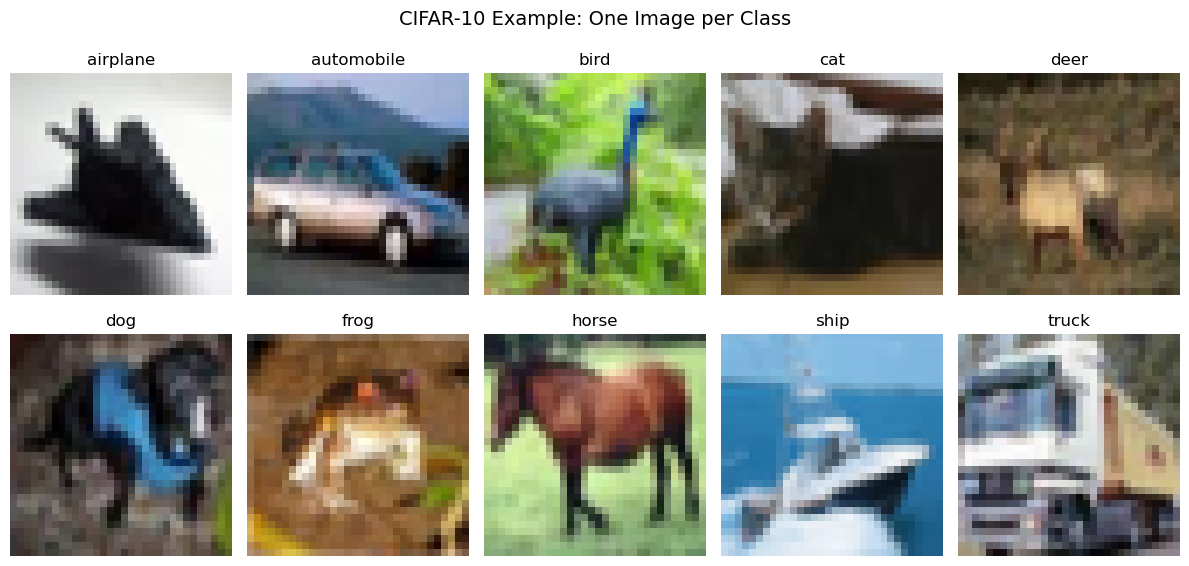

In [7]:
# Display one example per class
plt.figure(figsize=(12, 6))
for i in range(10):
    # Find the first occurrence of class i
    idx = np.where(y_train == i)[0][0]
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[idx])
    plt.title(class_names[i])
    plt.axis('off')
plt.suptitle("CIFAR-10 Example: One Image per Class", fontsize=14)
plt.tight_layout()
plt.show()

## Preprocess Data

In [8]:
# Normalize pixel values
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

In [9]:
# One-Hot Encode class labels (10 classes)
y_train = to_categorical(y_train, 10)
y_test  = to_categorical(y_test, 10)
print("After preprocessing:","\nX_train:", X_train.shape)
print("y_train:", y_train.shape)
print("Sample pixel range:", np.min(X_train), "→", np.max(X_train))

After preprocessing: 
X_train: (50000, 32, 32, 3)
y_train: (50000, 10)
Sample pixel range: 0.0 → 1.0


## Model

In [10]:
def make_optimizer(name:str, lr:float):
    name = name.lower()
    if name == "adam":    return Adam(learning_rate=lr)
    if name == "sgd":     return SGD(learning_rate=lr, momentum=0.9, nesterov=True)
    if name == "rmsprop": return RMSprop(learning_rate=lr)
    raise ValueError("Unknown optimizer: " + name)

def build_mlp(hidden_layers, activation="relu", dropout=0.0, optimizer="adam", lr=1e-3):
    """
    hidden_layers: tuple/list of units per hidden Dense layer, e.g. (512, 256)
    activation: 'relu' recommended
    dropout: 0.0 ~ 0.5 (applied after each hidden layer if >0)
    """
    model = Sequential()
    model.add(Flatten(input_shape=(32,32,3)))
    for units in hidden_layers:
        model.add(Dense(units, activation=activation))
        if dropout and dropout > 0:
            model.add(Dropout(dropout))
    model.add(Dense(10, activation='softmax'))  # 10 classes

    opt = make_optimizer(optimizer, lr)
    model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
    return model

def train_and_evaluate(model, X_train, y_train, X_test, y_test,
                       epochs=20, batch_size=128, verbose=1):
    # helpful callbacks
    es = EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)
    rlrop = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)

    history = model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[es, rlrop],
        verbose=verbose
    )
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    return history, test_loss, test_acc

In [56]:
# ---- Define candidate configs (kept compact so it runs fast) ----
configs = [
    # (hidden_layers, activation, dropout, optimizer, lr, batch_size)
    ((512, 256),      "relu", 0.30, "adam",    1e-3, 128),
    ((1024, 512, 256),"relu", 0.30, "adam",    1e-3, 128),
    ((512, 512, 256), "relu", 0.30, "adam",    3e-4, 128),
    ((512, 256),      "relu", 0.30, "sgd",     1e-2, 128),
    ((512, 256),      "relu", 0.30, "rmsprop", 1e-3, 128),
    # Try a different batch size
    ((512, 256),      "relu", 0.30, "adam",    1e-3, 64),
]

results = []
for i, (hidden_layers, act, drop, opt, lr, bs) in enumerate(configs, start=1):
    print(f"\n=== Run {i} ===")
    print(f"Arch={hidden_layers}, act={act}, dropout={drop}, opt={opt}, lr={lr}, batch={bs}")
    model = build_mlp(hidden_layers, activation=act, dropout=drop, optimizer=opt, lr=lr)
    history, test_loss, test_acc = train_and_evaluate(
        model, X_train, y_train, X_test, y_test, epochs=20, batch_size=bs, verbose=1
    )
    results.append({
        "run": i,
        "hidden_layers": hidden_layers,
        "activation": act,
        "dropout": drop,
        "optimizer": opt,
        "lr": lr,
        "batch_size": bs,
        "test_acc": float(test_acc),
        "test_loss": float(test_loss),
        "history": history,
        "model": model
    })

# Sort by best test accuracy
results = sorted(results, key=lambda r: r["test_acc"], reverse=True)

print("\n=== Summary (Top → Bottom) ===")
for r in results:
    print(f"Run {r['run']:>2}: acc={r['test_acc']*100:5.2f}% | arch={r['hidden_layers']} "
          f"| opt={r['optimizer']} lr={r['lr']} | bs={r['batch_size']} | drop={r['dropout']}")



=== Run 1 ===
Arch=(512, 256), act=relu, dropout=0.3, opt=adam, lr=0.001, batch=128

Epoch 1/20


313/313 [==============================] - 16s 44ms/step - loss: 2.0437 - accuracy: 0.2513 - val_loss: 1.8682 - val_accuracy: 0.3203 - lr: 0.0010
Epoch 2/20
313/313 [==============================] - 14s 44ms/step - loss: 1.8981 - accuracy: 0.3073 - val_loss: 1.8596 - val_accuracy: 0.3277 - lr: 0.0010
Epoch 3/20
313/313 [==============================] - 13s 43ms/step - loss: 1.8605 - accuracy: 0.3217 - val_loss: 1.7939 - val_accuracy: 0.3520 - lr: 0.0010
Epoch 4/20
313/313 [==============================] - 14s 44ms/step - loss: 1.8242 - accuracy: 0.3351 - val_loss: 1.7741 - val_accuracy: 0.3676 - lr: 0.0010
Epoch 5/20
313/313 [==============================] - 13s 41ms/step - loss: 1.7918 - accuracy: 0.3503 - val_loss: 1.7292 - val_accuracy: 0.3912 - lr: 0.0010
Epoch 6/20
313/313 [==============================] - 13s 42ms/step - loss: 1.7686 - accuracy: 0.3566 - val_loss: 1.7171 - val_

In [2]:
best = results[0]
best_hist = best["history"].history

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(best_hist['loss'], label='Train Loss')
plt.plot(best_hist['val_loss'], label='Val Loss')
plt.title('Best Model - Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1,2,2)
plt.plot(best_hist['accuracy'], label='Train Acc')
plt.plot(best_hist['val_accuracy'], label='Val Acc')
plt.title('Best Model - Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout(); plt.show()


NameError: name 'results' is not defined

In [ ]:
# Use best model for predictions
best_model = best["model"]

probs = best_model.predict(X_test, verbose=0)
pred_classes = np.argmax(probs, axis=1)
true_classes = np.argmax(y_test, axis=1)

# Friendly text output (first 10)
print("\n=== Classification Results (first 10 test samples) ===")
for i in range(10):
    top1 = pred_classes[i]
    conf = probs[i, top1]
    print(f"Sample {i+1:2d} → Predicted: {class_names[top1]:10s} (p={conf:0.3f}) | Actual: {class_names[true_classes[i]]}")

# A small gallery with predictions
plt.figure(figsize=(12,6))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(X_test[i])
    title = f"P:{class_names[pred_classes[i]]}\nT:{class_names[true_classes[i]]}"
    plt.title(title, fontsize=9)
    plt.axis('off')
plt.suptitle("CIFAR-10 Predictions (Best Model)", fontsize=14)
plt.tight_layout(); plt.show()
